In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from aif360.algorithms.preprocessing import LFR
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric


# Loading Data and Pre-Processing

In [10]:
# Assign column names for german dataset
german_columns = [
    "checking_status",
    "duration_months",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings",
    "employment_duration",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_duration",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

# Read data
adult = pd.read_csv(r"Data/adult.csv", na_values=["?"]).dropna().reset_index(drop=True)
german = pd.read_csv(r"Data/german.data", sep=r"\s+", header=None, names=german_columns)
compas = pd.read_csv(r"Data/propublica_data_for_fairml.csv")

# Remap protected attribute to female = 1, male = 0
# and desired outcome = 1, undesired = 0 for all datasets for consistency
german["credit_risk"] = german["credit_risk"].map({1: 1, 2: 0})
german["female"] = german["personal_status_sex"].map(
    {"A91": 0, "A93": 0, "A94": 0, "A92": 1, "A95": 1}
)
german["status"] = german["personal_status_sex"].map(
    {
        "A91": "divorced/separated",
        "A92": "divorced/separated/married",
        "A93": "single",
        "A94": "married/widowed",
        "A95": "single",
    }
)

adult["sex"] = adult["sex"].map({"Male": 0, "Female": 1})
adult["income"] = adult["income"].map({">50K": 1, "<=50K": 0})
adult = adult.rename(columns={"sex": "female"})

compas = compas.rename(columns={"Female": "female"})
compas["Two_yr_Recidivism"] = compas["Two_yr_Recidivism"].map({1: 0, 0: 1})

# Split data into features and target variables with one-hot-encoding for categorical features
german_X = pd.get_dummies(
    german.drop(["personal_status_sex", "status", "credit_risk"], axis=1), dtype=int
)
german_Y = german["credit_risk"]

adult_X = pd.get_dummies(adult.drop(["income"], axis=1), dtype=int)
adult_Y = adult["income"]

compas_X = compas.drop(["Two_yr_Recidivism", "score_factor"], axis=1)
compas_Y = compas["Two_yr_Recidivism"]

S = "female"

# Group with the lower favourable-outcome rate in the original labels.
# female = 1 means women; female = 0 means men.
unprivileged_values = {"Adult": 1, "German": 1, "COMPAS": 0}


# Fairness Metrics

In [11]:
# Define functions to quickly compute all 3 fairness measures


def AIF_dataset(X, Y):
    """Transform data into AIF BinaryLabelDataset"""

    return BinaryLabelDataset(
        df=pd.concat([X, Y], axis=1),
        label_names=[Y.name],
        protected_attribute_names=[S],
        favorable_label=1,
        unfavorable_label=0,
    )


def get_metrics(data, unprivileged_value=1):
    """Computes Demographic Parity difference, DI Ratio and Consistency"""

    metrics = BinaryLabelDatasetMetric(
        data,
        unprivileged_groups=[{S: unprivileged_value}],
        privileged_groups=[{S: 1 - unprivileged_value}],
    )

    # Positive DP_diff means a higher favourable rate for the privileged group.
    DP_diff = -metrics.statistical_parity_difference()
    DI_ratio = metrics.disparate_impact()
    consistency = metrics.consistency(n_neighbors=5).item()

    Results = {
        "Demographic Parity Difference": round(DP_diff, 4),
        "Disparate Impact Ratio": round(DI_ratio, 4),
        "Consistency": round(consistency, 4),
    }
    return Results


# Metrics for original labels

In [12]:
# Compute fairness measures on all 3 datasets
scores = {}
for dataset, X, Y in [
    ("Adult", adult_X, adult_Y),
    ("German", german_X, german_Y),
    ("COMPAS", compas_X, compas_Y),
]:
    data = AIF_dataset(X, Y)

    scores[dataset] = get_metrics(data, unprivileged_values[dataset])


In [13]:
unfair_metrics = pd.DataFrame(scores).T
unfair_metrics


,Demographic Parity Difference,Disparate Impact Ratio,Consistency
Adult,0.2002,0.3622,0.7628
German,0.0748,0.8966,0.6810
COMPAS,0.1280,0.8026,0.6188


# Train-Test split

In [14]:
# Create train test splits with stratification for each dataset
splits = {}

for dataset, X, Y in [
    ("Adult", adult_X, adult_Y),
    ("German", german_X, german_Y),
    ("COMPAS", compas_X, compas_Y),
]:
    X_train, X_test, Y_train, Y_test = train_test_split(
        X, Y, test_size=0.2, stratify=Y, random_state=42
    )

    scaler = MinMaxScaler().set_output(transform="pandas")

    splits[dataset] = {
        "X_train": scaler.fit_transform(X_train),
        "X_test": scaler.transform(X_test),
        "Y_train": Y_train,
        "Y_test": Y_test,
    }


# Fairness for mitigated labels

In [45]:
# Train LFR on the training data and apply the learned transformation to
# the test set and return the fairness measures and predictive performance

scores = {}
lfr_run = {}
for dataset, split in splits.items():
    print(f"start loop: {dataset}")

    train_data = AIF_dataset(split["X_train"], split["Y_train"])
    test_data = AIF_dataset(split["X_test"], split["Y_test"])

    lfr = LFR(
        unprivileged_groups=[{S: unprivileged_values[dataset]}],
        privileged_groups=[{S: 1 - unprivileged_values[dataset]}],
        k=5,
        Ax=0.01,
        Ay=0.9,
        Az=1,
        seed=42,
        verbose=1,
        print_interval=4000,
    )

    lfr.fit(train_data, maxiter=5000, maxfun=24000)

    test_transformed = lfr.transform(test_data)
    pred = test_transformed.labels.ravel()

    predicted_data = test_data.copy(deepcopy=True)
    predicted_data.labels = test_transformed.labels.copy()

    scores[dataset] = get_metrics(predicted_data, unprivileged_values[dataset])
    scores[dataset]["Accuracy"] = accuracy_score(split["Y_test"], pred)
    scores[dataset]["Balanced Accuracy"] = balanced_accuracy_score(
        split["Y_test"], pred
    )

    lfr_run[dataset] = {
        "model": lfr,
        "predictions": pred,
    }

    print(f"end loop: {dataset}")


start loop: Adult
step: 0, loss: 0.7138891671501199, L_x: 0.5289507198872259,  L_y: 0.7640880023290012,  L_z: 0.020920457855146467
step: 4000, loss: 0.49605241681834517, L_x: 0.5163883876626731,  L_y: 0.5321522988813281,  L_z: 0.01195146394852314
step: 8000, loss: 0.4260292428538552, L_x: 0.37529741534057603,  L_y: 0.4393555493316876,  L_z: 0.026856274301930598
step: 12000, loss: 0.4116600623653895, L_x: 0.37627990376190285,  L_y: 0.42917828090333904,  L_z: 0.02163681051476537
step: 16000, loss: 0.4116583779881015, L_x: 0.3762781578303926,  L_y: 0.429177160833944,  L_z: 0.021636151659247944
step: 20000, loss: 0.40270065940477445, L_x: 0.3354611038239744,  L_y: 0.4356023670762619,  L_z: 0.007303917997899001
step: 24000, loss: 0.4103012088036426, L_x: 0.29538045424466775,  L_y: 0.4414083911820159,  L_z: 0.010079852197381587
end loop: Adult
start loop: German
step: 0, loss: 0.6108614825140591, L_x: 0.5608509614266645,  L_y: 0.6492462588806811,  L_z: 0.020931339907179575
step: 4000, loss: 

In [46]:
fair_metrics = pd.DataFrame(scores).T
fair_metrics


,Demographic Parity Difference,Disparate Impact Ratio,Consistency,Accuracy,Balanced Accuracy
Adult,0.0257,0.7947,0.9854,0.811371,0.659226
German,-0.0214,1.0275,0.8290,0.725000,0.632143
COMPAS,0.0566,0.9063,0.9909,0.604049,0.599577


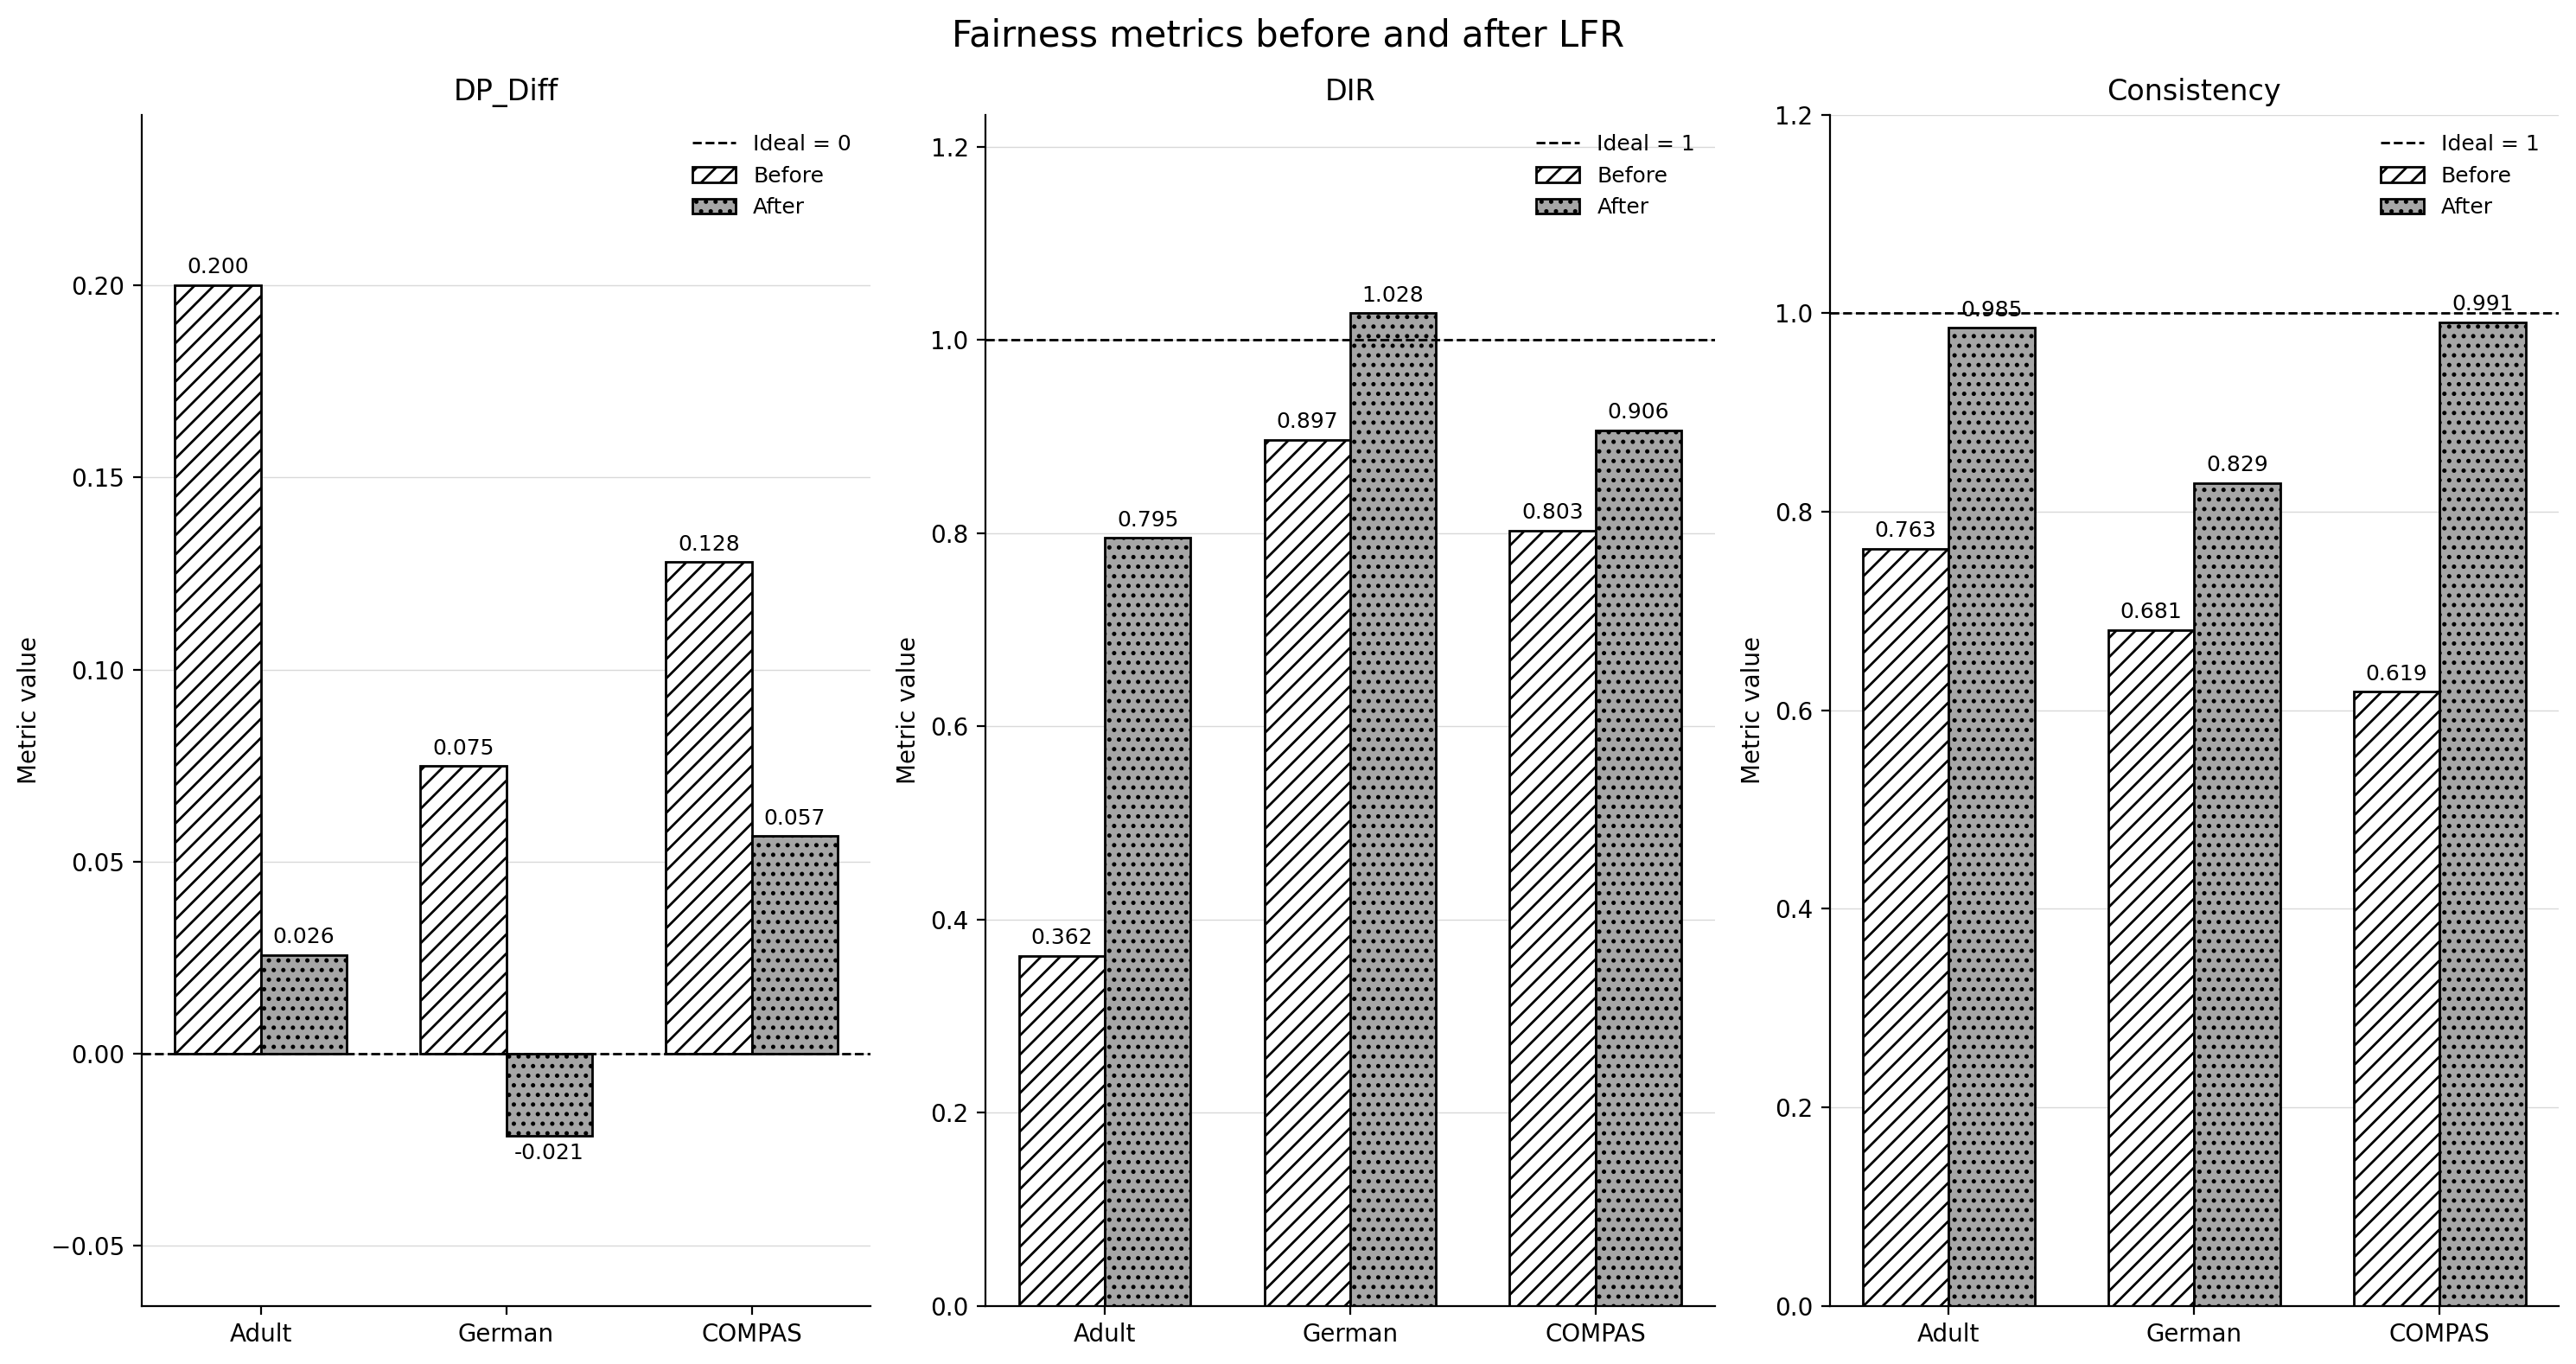

In [ ]:
# Plot metrics
datasets = ["Adult", "German", "COMPAS"]
metrics = [
    ("Demographic Parity Difference", "DP_Diff", 0),
    ("Disparate Impact Ratio", "DIR", 1),
    ("Consistency", "Consistency", 1),
]

x = np.arange(len(datasets))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(15, 8))

for ax, (column, title, ideal) in zip(axes, metrics):
    before = unfair_metrics.loc[datasets, column].to_numpy()
    after = fair_metrics.loc[datasets, column].to_numpy()

    bars_before = ax.bar(
        x - width / 2,
        before,
        width,
        label="Before",
        color="white",
        edgecolor="black",
        hatch="///",
    )
    bars_after = ax.bar(
        x + width / 2,
        after,
        width,
        label="After",
        color="0.65",
        edgecolor="black",
        hatch="...",
    )

    ax.axhline(
        ideal, color="black", linestyle="--", linewidth=1, label=f"Ideal = {ideal}"
    )

    ax.bar_label(bars_before, fmt="%.3f", padding=3, fontsize=9)
    ax.bar_label(bars_after, fmt="%.3f", padding=3, fontsize=9)

    ax.set_xticks(x, datasets)
    ax.set_title(title)
    ax.set_ylabel("Metric value")
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="0.85", linewidth=0.5)
    ax.margins(y=0.20)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=9, frameon=False)

fig.suptitle("Fairness metrics before and after LFR", fontsize=15)
fig.tight_layout()


plt.show()
